# Preprocessing the data: reading the intensity at regularly spaced wavenumbers

The model takes a fixed set of wavenumbers. Every file in the archives arrives on its own axis:
the spacings differ from file to file, and so do the two ends. Something has to put them all on
the same evenly spaced axis before the model reads them, and this notebook writes that step
down and runs it over one spectrum of the selected set. The sampling rule is the repository's,
in `src/cnn/cnn_preprocessing.py`; what is written out here is the same rule on the axis the
selected set needs.

The axis standardised to here is taken from the selected set: the window that set is built on,
100 to 1250 cm-1, read at the spacing the archives are mostly written on, 0.4821 cm-1. Both
numbers come from `notebooks/selected_data_eda.ipynb`. The step is the exact one and the ends
follow from it, so the axis stops just short of 1250 cm-1. The intensities come out in [0, 1].


## 1. Setting up

The repository's loader is imported, so the checkout has to be importable. It is found by
walking up from the working directory rather than assumed, because a kernel can start in
`notebooks/` rather than at the repository root.

The axis standardised to is built in the cell below, from the window the selected set is built
on and the step the archives are mostly written on. Both numbers are named there and nowhere
else, so the axis every later cell reads at cannot drift from the one printed beside it.


In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
from scipy.signal import find_peaks

%matplotlib inline

# Categorical slots are taken in a fixed order and never cycled.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
SURFACE, FLAG = "#fcfcfb", "#b3261e"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "text.color": INK,
    "font.size": 9,
    "legend.frameon": False,
    "figure.dpi": 110,
})

# The repository's loader is imported, so the checkout has to be on the path. A kernel
# can start in this directory rather than at the repository root, which is why the root is
# searched for rather than assumed.
ROOT = next((parent for parent in [Path.cwd(), *Path.cwd().parents]
             if (parent / "src" / "cnn" / "cnn_preprocessing.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(f"no checkout of SH_Project at or above {Path.cwd()}")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.loader import load_CNN_data

# The window the selected set is built on, the three numbers selected_data_eda.ipynb selects
# files by: the file has to reach 100 cm-1 or lower and end in 1250 to 1350 cm-1.
WINDOW_LOW, WINDOW_HIGH, KEEP_HIGH = 100.0, 1250.0, 1350.0

# The axis this notebook standardises to: the window, read at the spacing the archives are
# mostly written on. The step is exact, so the ends follow from it rather than the step from
# the ends, and the last point stops 0.19 cm-1 short of 1250: the window is 1150 cm-1 wide,
# which is 2385.4 steps of 0.4821.
SPACING = 0.4821
AXIS = np.arange(WINDOW_LOW, WINDOW_HIGH, SPACING)

UNCONFIRMED_MARKERS = ("not yet confirmed", "not confirmed", "unconfirmed")

DATA_ROOT = Path(os.environ.get("RRUFF_DATA", Path.home() / "Desktop" / "raman_data")).expanduser()

print(f"checkout: {ROOT}")
print(f"the axis standardised to here: {AXIS.size:,} points from {AXIS[0]:.4f} to "
      f"{AXIS[-1]:.4f} cm-1, {float(np.median(np.diff(AXIS))):.4f} cm-1 apart")


checkout: /home/raj/projects/SH_Project
the axis standardised to here: 2,386 points from 100.0000 to 1249.8085 cm-1, 0.4821 cm-1 apart


## 2. Where the repository samples the intensity

The sampling happens in one function, `standardise_data` in `src/cnn/cnn_preprocessing.py`. Three
of its lines do it:

```python
new_x = np.linspace(x_min, x_max, target_length)
f = interp1d(x, y, kind="linear", bounds_error=False, fill_value=0)
new_y = f(new_x)
```

Four things follow from them:

- the new axis holds `target_length` points from `x_min` to `x_max`, the ends included, so its
  spacing is `(x_max - x_min) / (target_length - 1)` and is the same for every spectrum;
- each new point takes the value read off the file's own points by straight-line
  interpolation, so it is exact where the two axes share a wavenumber and a blend between two
  file points in between;
- a new point that falls outside the file's own range reads as 0 rather than raising, which is
  how a file that does not reach one end of the axis is handled;
- `interp1d` puts the axis it is given in order before reading it, carrying each intensity
  along with its own wavenumber and keeping the file's order where a wavenumber repeats, so a
  file that repeats a wavenumber or steps backwards is sampled as though its axis rose.

The lines after the sampling are a separate step: negative values are clipped at zero, and the
values are divided by their peak, so every spectrum comes back in [0, 1].

What this notebook standardises to is a different axis from the configured one, and a different
one again in how it is built. It is the window the selected set is built on, and its ends
follow from the step rather than the step from its ends: `np.arange(100.0, 1250.0, 0.4821)`,
2386 points ending at 1249.8085 cm-1, because 1150 cm-1 is 2385.4 steps of 0.4821. The step is
the spacing the archives are mostly written on, so a file on that grid is read almost where it
was written. The rule above is what section 3 writes out; what changes here is the axis it is
applied to.

Nothing before this puts a spectrum on an even axis. `load_CNN_data` in `src/data/loader.py`
hands each file to ramanspy, whose RRUFF reader returns the file's own axis as it was written,
spacing and all.

The range and the point count the repository is configured with default in `TrainConfig` to
2000 points from 313.3 to 1028.4 cm-1, and `src/cnn/train.py` calls the function with
`cfg.input_size`, `cfg.x_min` and `cfg.x_max`. Prediction calls it with the same three read back
from the trained run's manifest (`src/cnn/predict.py`), after
`runs.check_axis_covers_training_range` has confirmed the map's own axis covers them.


## 3. The function

`sample_at_regular_spacing` is the sampling alone: it reads a file's two columns at the
wavenumbers of the shared axis it is given. `standardise_spectrum` is that plus the two steps
the repository applies after it, which is the whole of what one spectrum goes through before the
model reads it. Both work on the two columns a file holds rather than on the loader's object,
since that is the shape the EDA notebooks already carry.


In [2]:
def sample_at_regular_spacing(x, y, axis):
    """Read the intensity of one file at the wavenumbers of the shared axis.

    The model takes a fixed set of wavenumbers and a file arrives on its own axis, so every
    point of the shared axis takes the value read off the file's points by straight-line
    interpolation. The ends of the axis need not fall on a file's own points, so each one is
    read the same way as the points between them. A point outside the file's own range reads
    as zero, since the files disagree about where they start and stop. The axis is put in
    order first, each intensity carried along by its own wavenumber, which matters for the few
    files that repeat a wavenumber or step backwards.

    Args:
        x, y (np.ndarray): the wavenumbers and intensities as the file writes them.
        axis (np.ndarray): the wavenumbers to read at, in cm-1.

    Returns:
        np.ndarray: the intensity at each point of the axis.
    """
    read = interp1d(x, y, kind="linear", bounds_error=False, fill_value=0)
    return read(axis)


def standardise_spectrum(x, y, axis):
    """One spectrum read at the shared axis, clipped and scaled as the model takes it.

    The sampling above, then the two steps the repository applies to the sampled values: a
    value below zero becomes zero, because a raw spectrum is a photon count and cannot go
    below it, and the values are divided by their peak, which puts the spectrum in [0, 1] so
    that how bright the sample was does not decide what the model sees. The peak is read after
    the clip, so a spectrum whose highest point is negative comes back as zeros rather than as
    a set of negative values scaled up.

    Args:
        x, y (np.ndarray): the wavenumbers and intensities as the file writes them.
        axis (np.ndarray): the wavenumbers to read at, in cm-1.

    Returns:
        np.ndarray: the standardised intensity at each point of the axis, in [0, 1].
    """
    new_y = sample_at_regular_spacing(x, y, axis)
    new_y = np.clip(new_y, 0, None)
    return new_y / (new_y.max() + 1e-8)


## 4. One spectrum of the selected set, sampled

The spectrum comes in through the repository's own loader, so the file is read here as the
loader reads it. `unrated_unoriented` is the archive read because it is the smallest of the
seven that holds a spectrum meeting the selection, which keeps the cell quick; the file taken
is the first in it that meets the three conditions the selected set is built on, a RAW export
whose identification is confirmed and whose data reaches 100 cm-1 or lower and ends in 1250 to
1350 cm-1.


### Why the whole file is read, not the window

The sampler of section 3 handles a point that falls outside the file's own range by filling it
with 0 rather than raising, which is the third bullet of section 2. That fill is meant for a file
that does not reach one end of the axis at all, and it is easy to call up by accident: cut the
file to the window first, and the axis's own ends can then sit outside the data they are measured
from. A file's grid is laid down from wherever its export began, so the window almost never holds
a point at exactly 100.0, and the axis's first point lands in the gap and reads as 0. On this file
that zero would sit beside the tallest point in the window: the file measures 2153 at 99.6350 and
2129 at 100.1171 cm-1, so the model would read 0 immediately followed by the window's peak, one
fabricated step of the full range that the standardisation cannot dilute. Counted under the same
selection over the four unoriented archives, 3,459 of the 3,463 files put their first windowed
point above 100.0, so this is the usual case rather than an unlucky one.

Reading the whole file avoids it, and the window is not lost by doing so: the window is already
expressed by the axis. The file's points at 99.6350 and 100.1171 bracket the axis's first point,
so the value read there comes from two measurements instead of a fill, and the same holds at the
top, where 1249.4840 and 1249.9660 bracket 1249.8085. The cell below therefore hands the sampler
`x` and `y` as the loader returns them, and the window enters only as the axis. One consequence is
worth stating: the file's tallest point of all is at 92.8853 cm-1, below the window, so the value
interpolated at 100.0 (2135) is higher than any point the window holds (2129), and the divisor the
standardisation uses is that interpolated value.


In [3]:
def is_selected(meta, axis):
    """Whether one file belongs to the selected set.

    Args:
        meta (dict): the file's header fields as the loader returns them, keys prefixed.
        axis (np.ndarray): the file's own wavenumbers.

    Returns:
        bool: True for a RAW export, whose identification is confirmed, whose data reaches
        the window's low end or lower and ends between the window's high end and the top of
        the range the data is taken from.
    """
    if "RAW" not in meta.get("##FILETYPE", "").upper():
        return False
    if any(marker in meta.get("##STATUS", "").lower() for marker in UNCONFIRMED_MARKERS):
        return False
    return bool(axis.min() <= WINDOW_LOW and WINDOW_HIGH <= axis.max() <= KEEP_HIGH)


ARCHIVE = "unrated_unoriented"
spectra, metadata = load_CNN_data(str(DATA_ROOT / ARCHIVE))
spectrum, meta = next((taken, fields) for taken, fields in zip(spectra, metadata)
                      if is_selected(fields, np.asarray(taken.spectral_axis, dtype=float)))

x = np.asarray(spectrum.spectral_axis, dtype=float)
y = np.asarray(spectrum.spectral_data, dtype=float)

# The whole file goes to the sampler, not the part of it the window holds. Cutting the file to
# the window first would add nothing except the gap between the window's edge and the file's
# nearest point, and the axis's end would then fall in that gap and be filled with 0 rather than
# interpolated. Read whole, the file's own points bracket the axis at both ends.
sampled = standardise_spectrum(x, y, AXIS)

inside = (x >= WINDOW_LOW) & (x <= WINDOW_HIGH)
outside = (AXIS < x.min()) | (AXIS > x.max())
covers_axis = bool(x.min() <= AXIS[0] and x.max() >= AXIS[-1])

print(f"{ARCHIVE}, {meta.get('##NAMES')} {meta.get('##RRUFFID')}:")
print(f"  the file:        {x.size:,} points from {x.min():.4g} to {x.max():.4g} cm-1, "
      f"{np.median(np.diff(x)):.4f} cm-1 apart")
print(f"  the window:      {int(inside.sum()):,} of them, {x[inside].min():.4g} to "
      f"{x[inside].max():.4g} cm-1")
print(f"  the sampled axis: {AXIS.size:,} points from {AXIS[0]:.4f} to {AXIS[-1]:.4f} cm-1, "
      f"{SPACING:.4f} cm-1 apart")
print(f"  the file's own range covers the sampled axis: {covers_axis}")
print(f"  sampled points falling outside the file, which read as 0: {int(outside.sum()):,}")
print(f"  the standardised spectrum peaks at {sampled.max():.6f} at {AXIS[sampled.argmax()]:.4f} "
      f"cm-1, lowest value {sampled.min():.6f}")


unrated_unoriented, Pigeonite R200002:
  the file:        2,479 points from 87.58 to 1282 cm-1, 0.4821 cm-1 apart
  the window:      2,386 of them, 100.1 to 1250 cm-1
  the sampled axis: 2,386 points from 100.0000 to 1249.8085 cm-1, 0.4821 cm-1 apart
  the file's own range covers the sampled axis: True
  sampled points falling outside the file, which read as 0: 0
  the standardised spectrum peaks at 1.000000 at 100.0000 cm-1, lowest value 0.168459


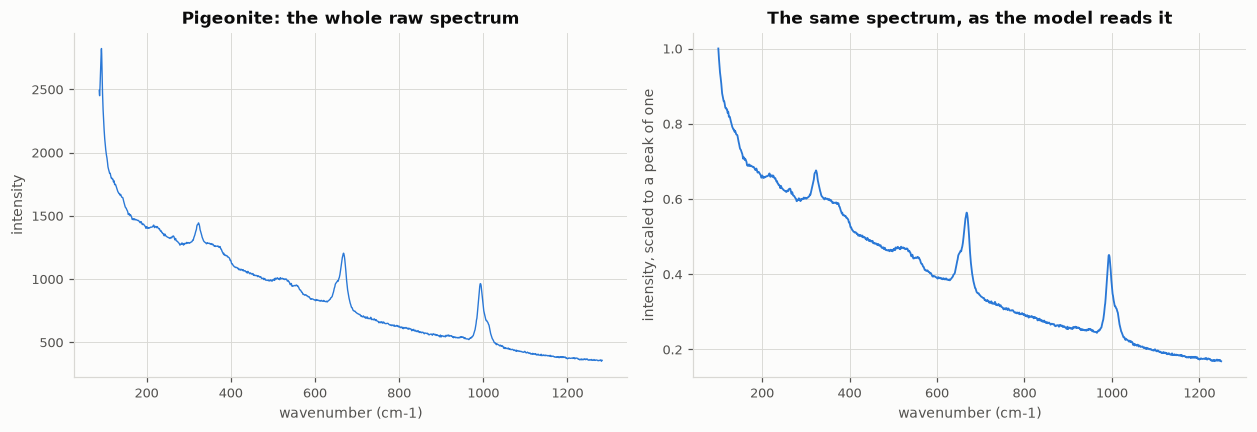

In [4]:
# The whole file as the export wrote it, then the same spectrum as the model reads it: the
# window on the shared axis, clipped at zero and scaled to a peak of one. The file runs wider
# than the window, so the first panel holds points the model never sees.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))

axes[0].plot(x, y, color=BLUE, lw=0.9)
axes[0].set_title(f"{meta.get('##NAMES')}: the whole raw spectrum")
axes[0].set_xlabel("wavenumber (cm-1)")
axes[0].set_ylabel("intensity")

axes[1].plot(AXIS, sampled, color=BLUE, lw=1.2)
axes[1].set_title("The same spectrum, as the model reads it")
axes[1].set_xlabel("wavenumber (cm-1)")
axes[1].set_ylabel("intensity, scaled to a peak of one")
plt.tight_layout()
plt.show()


## 5. What the resampling costs

The pre-processed curve is judged against the file's own points, never against another reading of
the same curve: a curve compared with itself scores perfectly whatever the grid. The comparison is
made across the wavenumber range the two share, and it is made there exactly rather than by reading
one curve on the other's grid: both curves are straight lines between the wavenumbers they are
written at, so across the union of the two grids the difference between them is a straight line on
every interval, its largest value is reached at a knot, and its mean square follows from Simpson's
rule. Both are put on the scale the standardisation uses rather than on their own, since a curve
put on its own scale would have exactly the flattening this is measuring scaled away from it.

Across the common range the pre-processed curve differs from the file's by 0.0925% of the scaled
peak at its worst, with a root mean square of 0.0112%, a correlation of 0.99999972, and a
spectral angle of 0.018 degrees. Cosine similarity is deliberately not reported beside the
angle: it is `cos(angle)`, so the two are one number in two units.

### What the four numbers are

Each of them is read off one difference: the pre-processed curve less the file's, wavenumber by
wavenumber across the range the two share. Both curves are divided by the same divisor before
anything is subtracted, and that divisor is the largest value the model's own curve reaches on its
axis, 2135.04 counts here. A percentage is therefore a share of the peak the model is scaled to,
which keeps a change in the model's overall level visible instead of cancelling it. The divisor is
deliberately not the file's own largest value: that sits at 92.89 cm-1, outside the window, so
dividing by it would shrink both curves inside the range without measuring anything. One
consequence is worth stating plainly, the file's own largest point inside the range reads 0.9973 of
the model's peak rather than 1.0000, so a level difference of that size would show up in these
numbers rather than being divided away.

- **Largest difference** is the greatest absolute value the difference takes over the common
  range. It is reached at a knot rather than between two of them, since the difference is a
  straight line on every interval between knots.
- **Root mean square** is the square root of the mean of the squared difference over the common
  range, taken against wavenumber rather than against index, so a stretch of axis carrying more
  points does not weigh more than a short one. It is exact rather than sampled: Simpson's rule is
  exact on each interval because the squared difference is a quadratic there.
- **Correlation** is Pearson's between the two curves, both read at the union grid's knots, so at
  the same wavenumbers. By construction it is blind to level, any positive multiple of the file's
  curve scores one, so it measures agreement in shape alone and says nothing about the divisor
  above.
- **1 - correlation** is the same number written the other way up, tabulated in the search below
  because the correlation itself reads 0.9999997 and every departure lives in the seventh decimal,
  where a column of nines shows nothing.


The second cell takes the comparison peak by peak, on the file's own points. Peaks are found above
a threshold, matched in the pre-processed curve within two axis steps, and each matched pair
contributes its position shift, its height change and its area change, while a peak with no
partner is counted as lost.

This file is already written at 0.4821 cm-1, so the resampling has little to do and the numbers
come out small: the apexes hold their position to within a step, no height loses more than a third
of a percent, and the area under the whole curve is unchanged to three decimals. The differences
are not systematic but point to point, since how far a point moves depends on how far it sits from
an axis point, and they are largest on the steep low-wavenumber tail, where the curve bends
hardest and a straight line between two axis points cuts the corner deepest.

The threshold is a choice rather than a fact about the spectrum: raising it counts fewer peaks and
leaves fewer that can be lost, without moving the shifts or the angle much. Here it runs over the
one spectrum of section 4; over the whole selected set the same computation gives the population
of these numbers.


In [5]:
# The cost of one spacing: the numbers section 5 reports and the arrays the cells below read.
# The pre-processed curve is judged against the file's own points across the wavenumber range the
# two share, which is the window narrowed by the file's own ends. The file read is the one section
# 4 loaded, which is why it is not passed in.


def spectral_angle(a, b):
    """The angle between two spectra taken as vectors, in degrees.

    Zero when one curve is a positive multiple of the other, which is what makes it blind to a
    change of scale, and undefined for a curve of zeros, which is reported as NaN rather than
    raised.

    Args:
        a, b (np.ndarray): the two curves, at the same wavenumbers.

    Returns:
        float: the angle in degrees, or NaN when either curve is all zeros.
    """
    scale = float(np.linalg.norm(a) * np.linalg.norm(b))
    if scale == 0.0:
        return float("nan")
    return float(np.degrees(np.arccos(np.clip(float(np.dot(a, b)) / scale, -1.0, 1.0))))


def closeness(spacing):
    """How far the pre-processed curve sits from the file's own curve at one spacing.

    Both curves are put on the scale the standardisation uses rather than on their own, since a
    curve put on its own scale would have exactly the flattening being measured scaled away from
    it. Each is a straight line between the wavenumbers it is written at, so across the union of
    the two grids the difference between them is a straight line on every interval: its largest
    value is reached at a knot, and its mean square follows from Simpson's rule, which is exact on
    each interval because the integrand is a quadratic there.

    Args:
        spacing (float): the step of the axis to standardise to, in cm-1.

    Returns:
        dict: the ends of the common range, the axis and the number of points on it, the file's
        own curve and the pre-processed curve divided by the same divisor, the union grid, the
        difference between the two curves on it, the largest difference and the root mean square
        across the range as a percent of the peak the model is scaled to, and the correlation and
        the spectral angle between the two curves.
    """
    axis = np.arange(WINDOW_LOW, WINDOW_HIGH, spacing)
    raw = np.clip(sample_at_regular_spacing(x, y, axis), 0, None)
    divisor = float(raw.max()) + 1e-8
    preprocessed = raw / divisor
    measured = np.clip(y, 0, None) / divisor

    low = max(float(x.min()), float(axis[0]))
    high = min(float(x.max()), float(axis[-1]))
    knots = np.unique(np.concatenate([x[(x >= low) & (x <= high)],
                                      axis[(axis >= low) & (axis <= high)]]))
    file_curve = np.interp(knots, x, measured)
    model_curve = np.interp(knots, axis, preprocessed)
    difference = model_curve - file_curve
    midpoints = 0.5 * (knots[1:] + knots[:-1])
    mid_difference = (np.interp(midpoints, axis, preprocessed)
                      - np.interp(midpoints, x, measured))
    steps = np.diff(knots)
    mean_square = np.sum((steps / 6.0) * (difference[:-1] ** 2 + 4.0 * mid_difference ** 2
                                          + difference[1:] ** 2)) / (high - low)
    return {
        "spacing": float(spacing),
        "axis": axis,
        "points": int(axis.size),
        "divisor": divisor,
        "low": low,
        "high": high,
        "measured": measured,
        "preprocessed": preprocessed,
        "knots": knots,
        "difference": difference,
        "largest": 100.0 * float(np.abs(difference).max()),
        "rms": 100.0 * float(np.sqrt(mean_square)),
        "correlation": float(np.corrcoef(file_curve, model_curve)[0, 1]),
        "angle": spectral_angle(file_curve, model_curve),
    }


cost = closeness(SPACING)
sampled_axis = cost["axis"]
common_low, common_high = cost["low"], cost["high"]
knots, difference = cost["knots"], cost["difference"]
preprocessed, measured = cost["preprocessed"], cost["measured"]

print(f"the common range: {common_low:.4f} to {common_high:.4f} cm-1, "
      f"{int(np.count_nonzero((x >= common_low) & (x <= common_high))):,} of the file's points "
      f"and {cost['points']:,} of the model's, giving {knots.size:,} knots between them")
print("the pre-processed curve against the file's across it, as a percent of the peak the model "
      "is scaled to:")
print(f"  largest difference   {cost['largest']:.4f}%")
print(f"  root mean square     {cost['rms']:.4f}%")
# The angle and the correlation are read on the same union grid, where the range is described
# twice over: as a weighted average of the curve, rather than an average of its values.
print(f"  correlation          {cost['correlation']:.8f}")
print(f"  spectral angle       {cost['angle']:.3f} degrees")

# What the four lines above are read from, so they stand on their own: the difference is a level in
# shares of the divisor, and the largest of it has a place in the range.
worst = int(np.argmax(np.abs(difference)))
model_at_worst = float(np.interp(knots[worst], sampled_axis, preprocessed))
inside = (x >= common_low) & (x <= common_high)
print(f"the difference is in shares of {cost['divisor']:.2f} counts, the largest value the model "
      f"reaches on its own axis; the file's own largest point inside the range is "
      f"{float(np.clip(y, 0, None)[inside].max()) / cost['divisor']:.4f} of that")
print(f"the largest difference sits at {knots[worst]:.4f} cm-1, where the model reads "
      f"{100.0 * model_at_worst:.2f}% of its peak and the file "
      f"{100.0 * (model_at_worst - difference[worst]):.2f}%")
print(f"of the {knots.size:,} knots, {int(np.count_nonzero(x[(x >= common_low) & (x <= common_high)])):,} "
      f"are the file's own wavenumbers and the rest are the axis's, which is why the range is "
      f"described twice over rather than sampled on one grid")


the common range: 100.0000 to 1249.8085 cm-1, 2,385 of the file's points and 2,386 of the model's, giving 4,771 knots between them
the pre-processed curve against the file's across it, as a percent of the peak the model is scaled to:
  largest difference   0.0925%
  root mean square     0.0112%
  correlation          0.99999972
  spectral angle       0.018 degrees
the difference is in shares of 2135.04 counts, the largest value the model reaches on its own axis; the file's own largest point inside the range is 0.9973 of that
the largest difference sits at 121.3302 cm-1, where the model reads 82.89% of its peak and the file 82.80%
of the 4,771 knots, 2,385 are the file's own wavenumbers and the rest are the axis's, which is why the range is described twice over rather than sampled on one grid


the file's own points inside the common range: 2,385 of its 2,479
peaks on the file's curve above 0.5% of the scaled peak: 17
  matched in the pre-processed curve: 14, lost: 3
  left out of the area column, their window off the end or too narrow to integrate: 0
  peaks in the pre-processed curve with no partner on the file's: 0
the area under the whole curve, file against pre-processed: +0.000%

 wavenumber  shift/step     height       area
      200.9      0.00s    -0.093%    -0.000%
      216.8      0.00s    -0.020%    -0.010%
      243.3      0.00s    -0.088%     0.008%
      263.6      0.00s    -0.026%    -0.011%
      268.9       lost
      284.3      0.00s    -0.059%     0.003%
      323.3      0.00s    -0.069%    -0.011%
      440.5      1.00s    -0.070%     0.031%
      510.4      0.00s    -0.086%    -0.001%
      517.6      0.00s    -0.118%     0.003%
      668.1      0.00s    -0.065%    -0.037%
      732.7      0.00s    -0.174%     0.001%
      882.1       lost
      898.0   

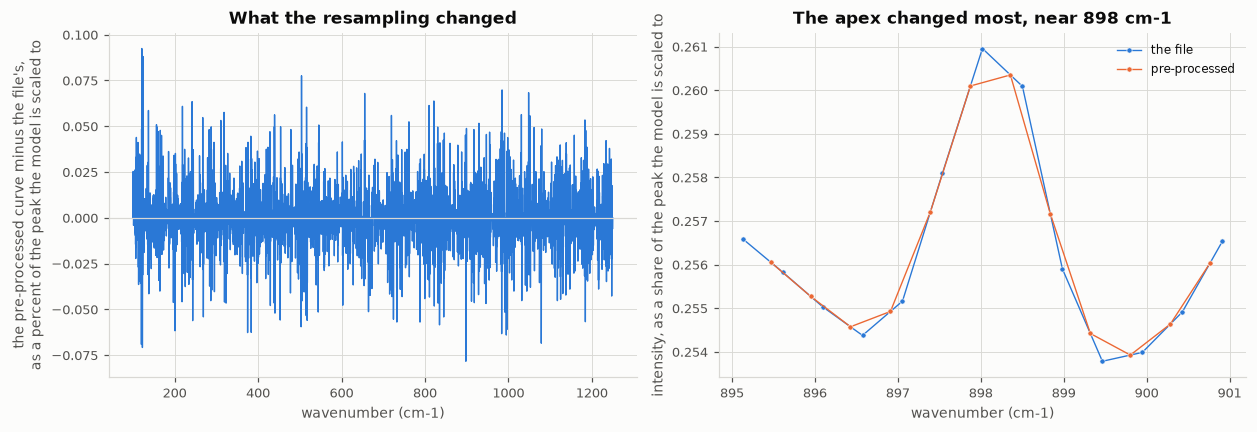

In [6]:
# Peaks are found on the file's own points, where the values are measurements rather than
# interpolated, and matched in the pre-processed curve by nearest wavenumber within two axis
# steps. An apex with no partner is counted as lost rather than as moved: the curve may still
# bend there, but not enough for the threshold to call it a peak.
#
# The windows are written in wavenumbers, at two and five steps of the notebook's own axis, rather
# than in steps of whatever spacing is being measured, so that a candidate spacing is judged by
# one rule throughout and its row can be read against any other. Section 6 also shows what the
# peak metrics come to under a rule that scales with the spacing instead. The apex detection is
# done on the file's own points whatever the spacing, and the prominence threshold is a share of
# the scaled peak rather than a distance, so neither of those moves with the spacing at all.
PROMINENCE = 0.005            # a peak rises this share of the peak the model is scaled to
HALF_WIDTH = 5 * SPACING      # the window a peak's area is taken over, on either curve
NEIGHBOURHOOD = 2 * SPACING   # how far an apex may move and still be the same peak


def peaks_against(cost, neighbourhood=NEIGHBOURHOOD, half_width=HALF_WIDTH):
    """How the peaks of the pre-processed curve stand against the file's own.

    Args:
        cost (dict): one spacing's cost, as `closeness` returns it.
        neighbourhood (float): how far an apex may move and still be the same peak, in cm-1.
        half_width (float): the window a peak's area is taken over, on either curve, in cm-1.

    Returns:
        dict: the file's wavenumbers inside the common range and the two curves read at them, the
        peaks found on each, one row per peak of the file's own (its wavenumber, and its shift in
        cm-1, its height change and its area change, any of which is None or NaN where the peak
        has no partner or its window runs off the end), and the counts and extremes drawn from
        those rows.
    """
    inside = (x >= cost["low"]) & (x <= cost["high"])
    grid_x = x[inside]
    reference = cost["measured"][inside]
    modelled = np.interp(grid_x, cost["axis"], cost["preprocessed"])

    reference_peaks, _ = find_peaks(reference, prominence=PROMINENCE)
    modelled_peaks, _ = find_peaks(modelled, prominence=PROMINENCE)

    rows, lost, no_area = [], 0, 0
    for index in reference_peaks:
        here = float(grid_x[index])
        partners = [other for other in modelled_peaks
                    if abs(grid_x[other] - here) <= neighbourhood]
        if not partners:
            rows.append({"wavenumber": here, "shift": None, "height": None, "area": None})
            lost += 1
            continue
        partner = min(partners, key=lambda other: abs(grid_x[other] - here))
        row = {
            "wavenumber": here,
            "shift": float(grid_x[partner] - here),
            "height": 100.0 * float(modelled[partner] / reference[index] - 1.0),
        }
        # An area whose window runs off either end of the common range is short by whatever lies
        # beyond it, and one narrower than the file's own step holds a single point, whose
        # trapezoid is zero and whose ratio is not a number. Both are counted and left out of the
        # area column rather than reported as a small or an infinite change.
        mine = np.abs(grid_x - here) <= half_width
        theirs = np.abs(grid_x - grid_x[partner]) <= half_width
        if (here - half_width >= grid_x[0] and here + half_width <= grid_x[-1]
                and np.count_nonzero(mine) > 1 and np.count_nonzero(theirs) > 1):
            row["area"] = 100.0 * float(np.trapezoid(modelled[theirs], grid_x[theirs])
                                        / np.trapezoid(reference[mine], grid_x[mine]) - 1.0)
        else:
            no_area += 1
            row["area"] = float("nan")
        rows.append(row)

    created = sum(1 for other in modelled_peaks
                  if not any(abs(grid_x[other] - grid_x[index]) <= neighbourhood
                             for index in reference_peaks))
    matched = [row for row in rows if row["shift"] is not None]
    shifts = np.abs([row["shift"] for row in matched])
    heights = np.array([row["height"] for row in matched])
    areas = np.array([row["area"] for row in matched if np.isfinite(row["area"])])
    return {
        "grid_x": grid_x,
        "reference": reference,
        "modelled": modelled,
        "reference_peaks": reference_peaks,
        "rows": rows,
        "matched": matched,
        "lost": lost,
        "no_area": no_area,
        "created": created,
        "shift_median": float(np.median(shifts)) if shifts.size else float("nan"),
        "shift_largest": float(shifts.max()) if shifts.size else float("nan"),
        "height_median": float(np.median(heights)) if heights.size else float("nan"),
        "height_worst": float(heights.min()) if heights.size else float("nan"),
        "area_median": float(np.median(areas)) if areas.size else float("nan"),
        "area_worst": float(areas.min()) if areas.size else float("nan"),
    }


peaks = peaks_against(cost)
grid_x, reference, modelled = peaks["grid_x"], peaks["reference"], peaks["modelled"]

print(f"the file's own points inside the common range: {grid_x.size:,} of its {x.size:,}")
print(f"peaks on the file's curve above {PROMINENCE:.1%} of the scaled peak: "
      f"{peaks['reference_peaks'].size:,}")
print(f"  matched in the pre-processed curve: {len(peaks['rows']) - peaks['lost']:,}, "
      f"lost: {peaks['lost']:,}")
print(f"  left out of the area column, their window off the end or too narrow to integrate: {peaks['no_area']:,}")
print(f"  peaks in the pre-processed curve with no partner on the file's: {peaks['created']:,}")
print(f"the area under the whole curve, file against pre-processed: "
      f"{100.0 * (np.trapezoid(modelled, grid_x) / np.trapezoid(reference, grid_x) - 1.0):+.3f}%")
print()
print(f"{'wavenumber':>11s} {'shift/step':>11s} {'height':>10s} {'area':>10s}")
for row in peaks["rows"]:
    if row["shift"] is None:
        print(f"{row['wavenumber']:11.1f} {'lost':>10s}")
        continue
    print(f"{row['wavenumber']:11.1f} {row['shift'] / SPACING:9.2f}s {row['height']:9.3f}% "
          f"{row['area']:9.3f}%")

if peaks["matched"]:
    print()
    print(f"shift:  median {peaks['shift_median'] / SPACING:.2f} steps, "
          f"largest {peaks['shift_largest'] / SPACING:.2f} steps")
    print(f"height: median {peaks['height_median']:+.3f}%, "
          f"largest drop {peaks['height_worst']:+.3f}%")
    if np.isfinite(peaks["area_median"]):
        print(f"area:   median {peaks['area_median']:+.3f}%, "
              f"largest drop {peaks['area_worst']:+.3f}%")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))

axes[0].plot(knots, 100.0 * difference, color=BLUE, lw=0.9)
axes[0].axhline(0.0, color=GRID, lw=0.8)
axes[0].set_title("What the resampling changed")
axes[0].set_xlabel("wavenumber (cm-1)")
axes[0].set_ylabel("the pre-processed curve minus the file's,\nas a percent of the peak the "
                   "model is scaled to")

# The apex the resampling moved most, drawn as the two curves rather than as their difference.
# Each is drawn at its own wavenumbers, so the two grids can be seen to interleave: the file's
# points sit a fraction of a step from the axis points, and an apex lands on a different one of
# each.
apexes = [int(np.argmin(np.abs(grid_x - row["wavenumber"]))) for row in peaks["matched"]]
worst = apexes[int(np.argmax(np.abs(modelled[apexes] - reference[apexes])))]
near = (grid_x >= grid_x[worst] - 3.0) & (grid_x <= grid_x[worst] + 3.0)
near_axis = (sampled_axis >= grid_x[worst] - 3.0) & (sampled_axis <= grid_x[worst] + 3.0)
axes[1].plot(grid_x[near], reference[near], color=BLUE, lw=0.9, marker="o", ms=3.4,
             markeredgecolor=SURFACE, markeredgewidth=0.4, label="the file")
axes[1].plot(sampled_axis[near_axis], preprocessed[near_axis], color=ORANGE, lw=0.9, marker="o",
             ms=3.4, markeredgecolor=SURFACE, markeredgewidth=0.4,
             label="pre-processed")
axes[1].set_title(f"The apex changed most, near {grid_x[worst]:.0f} cm-1")
axes[1].set_xlabel("wavenumber (cm-1)")
axes[1].set_ylabel("intensity, as a share of the peak the model is scaled to")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()


### What each metric measures, drawn

The panels below draw what the numbers above are read from. Each shows the same pair of curves,
the file's own and the pre-processed one, and each isolates the single thing its metric is taken
from, at the notebook's own 0.4821 cm-1 spacing, so the values printed in section 5 can be seen
rather than taken on trust.

Two of the metrics are not drawn. The spectral angle is the angle between the two curves read as
vectors of their values, which is the comparison the correlation panel makes before each curve
has its mean taken out of it; an angle between two vectors of some four thousand numbers has no
picture in a panel. The area under the whole curve is the area panel of the peak below, taken
across the shared range rather than across one window.


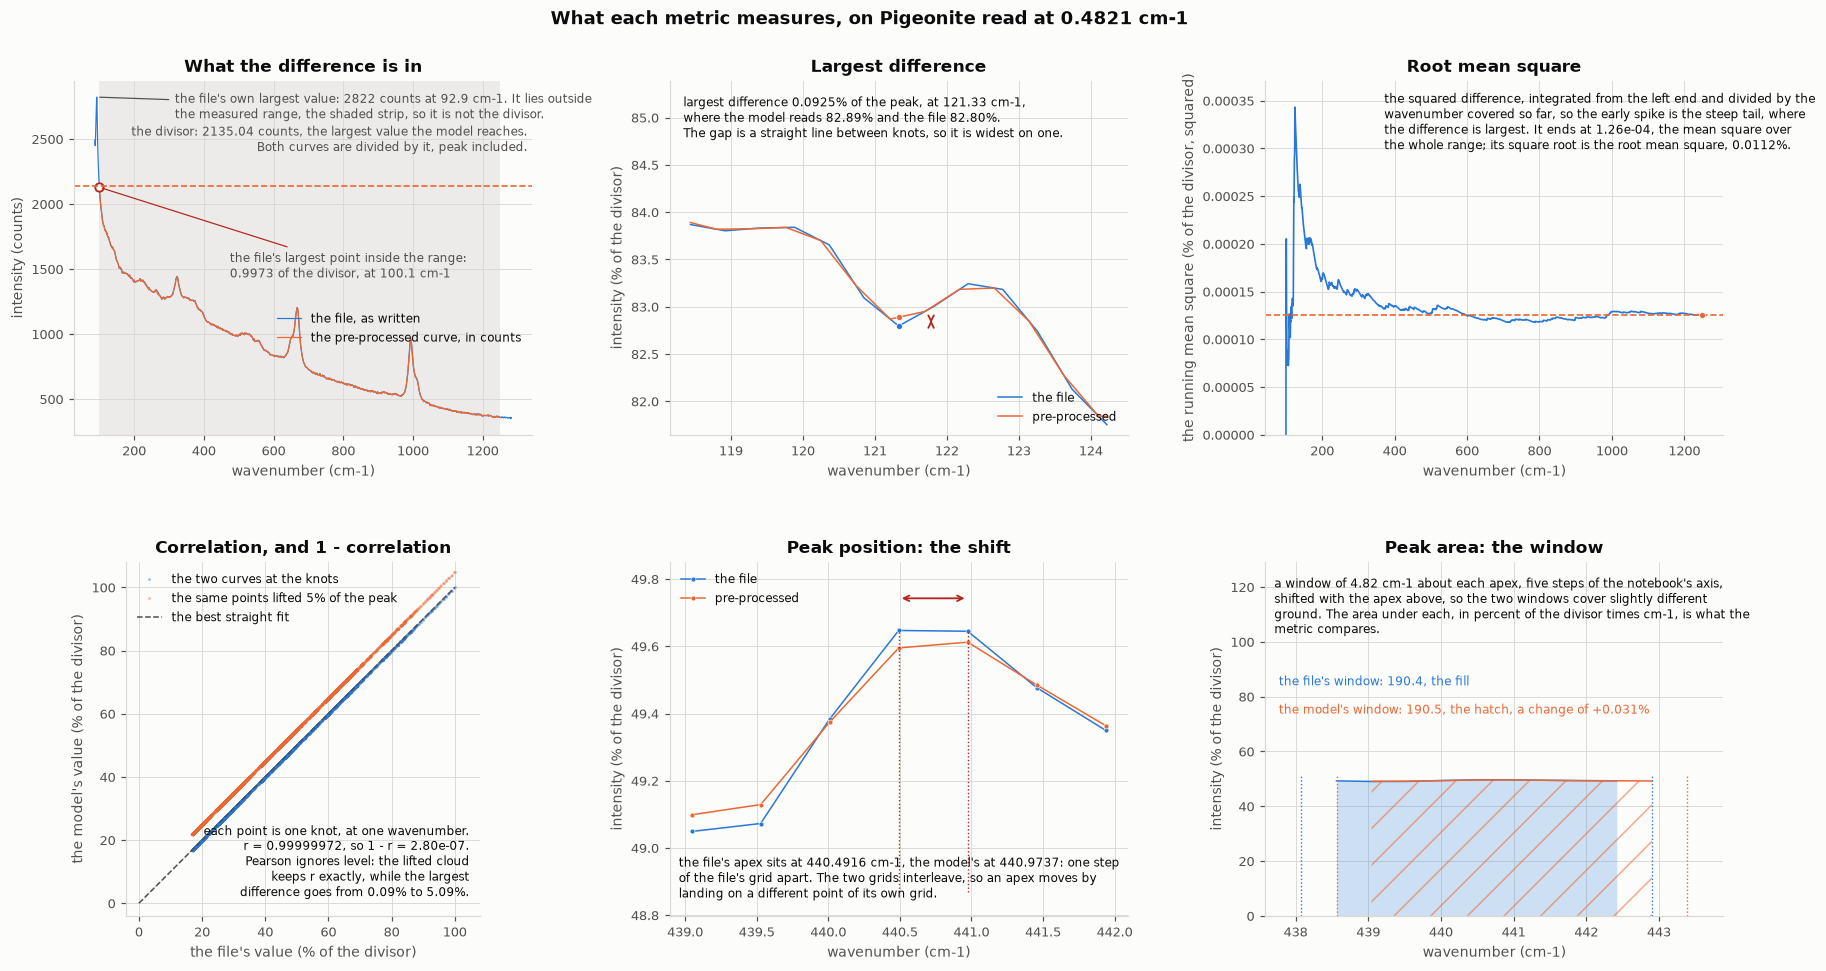

In [7]:
# Each panel draws what one metric is read from, on the same two curves at the notebook's own
# spacing: the file's own points and the pre-processed curve. The values section 5 prints are
# annotated onto the panel that produces them.
file_share = 100.0 * np.interp(knots, x, measured)
model_share = 100.0 * np.interp(knots, sampled_axis, preprocessed)
squared = (100.0 * difference) ** 2
midpoints = 0.5 * (knots[1:] + knots[:-1])
mid_squared = (100.0 * (np.interp(midpoints, sampled_axis, preprocessed)
                        - np.interp(midpoints, x, measured))) ** 2
mean_square_shown = cost["rms"] ** 2
worst_knot = int(np.argmax(np.abs(difference)))
worst_at = float(knots[worst_knot])
model_at_worst = float(model_share[worst_knot])
file_at_worst = float(file_share[worst_knot])

# The running mean square: the squared difference integrated from the left end of the range, at
# every knot, divided by the wavenumber covered so far. It is the same Simpson sum the metric uses,
# read before the square root, so it ends at the mean square and shows where that average is
# earned. The first point stands at zero because no wavenumber has been covered yet.
simpson_part = (np.diff(knots) / 6.0) * (squared[:-1] + 4.0 * mid_squared + squared[1:])
covered = knots - knots[0]
running = np.divide(np.concatenate([[0.0], np.cumsum(simpson_part)]), covered,
                    out=np.zeros_like(knots), where=covered > 0)

# The lift the correlation panel uses, and what it does to the largest difference: the correlation
# is invariant to a shift of either curve, the largest difference is not.
LIFT = 5.0
lifted_largest = 100.0 * float(np.abs(difference + LIFT / 100.0).max())

# The file's own largest value lies outside the measured range, so the largest one inside it is
# found as well: it is the point the divisor is compared against.
inside_range = (x >= common_low) & (x <= common_high)
file_inside = y[inside_range]
in_range_y = float(file_inside.max())
in_range_x = float(x[inside_range][int(np.argmax(file_inside))])
tallest = int(np.argmax(y))

# The peak the position and area panels draw: the one whose apex moves furthest and whose window is
# inside the range, so both panels have a real move and a real area to show.
with_area = [row for row in peaks["matched"] if np.isfinite(row["area"])]
drawn = max(with_area, key=lambda row: abs(row["shift"])) if with_area else None

fig, axes = plt.subplots(2, 3, figsize=(16.0, 9.2))
fig.suptitle(f"What each metric measures, on {meta.get('##NAMES')} read at {SPACING:.4f} cm-1",
             y=0.965, fontsize=12, fontweight="bold")

# What the difference is in: both curves over the whole file against the one divisor they are
# divided by, and the file's own largest value, which is not that divisor because it lies outside
# the measured range.
ax = axes[0, 0]
ax.axvspan(common_low, common_high, color=GRID, alpha=0.45, lw=0, zorder=0)
ax.plot(x, y, color=BLUE, lw=0.8, label="the file, as written")
ax.plot(sampled_axis, preprocessed * cost["divisor"], color=ORANGE, lw=0.8,
        label="the pre-processed curve, in counts")
ax.plot([in_range_x], [in_range_y], marker="o", ms=5.5, markerfacecolor=SURFACE,
        markeredgecolor=FLAG, markeredgewidth=1.2)
ax.axhline(cost["divisor"], color=ORANGE, ls="--", lw=1.1)
ax.annotate(f"the file's own largest value: {y[tallest]:.0f} counts at {x[tallest]:.1f} cm-1. "
            f"It lies outside\nthe measured range, the shaded strip, so it is not the divisor.",
            xy=(x[tallest], y[tallest]), xytext=(0.22, 0.97), textcoords="axes fraction",
            fontsize=8, color=INK_SOFT, va="top",
            arrowprops=dict(arrowstyle="-", color=INK_SOFT, lw=0.8))
ax.annotate(f"the file's largest point inside the range:\n"
            f"{in_range_y / cost['divisor']:.4f} of the divisor, at {in_range_x:.1f} cm-1",
            xy=(in_range_x, in_range_y), xytext=(0.34, 0.52), textcoords="axes fraction",
            fontsize=8, color=INK_SOFT, va="top",
            arrowprops=dict(arrowstyle="-", color=FLAG, lw=0.8))
ax.text(0.99, 0.79, f"the divisor: {cost['divisor']:.2f} counts, the largest value the model "
        f"reaches.\nBoth curves are divided by it, peak included.", transform=ax.transAxes,
        fontsize=8, color=INK_SOFT, va="bottom", ha="right")
ax.set_title("What the difference is in")
ax.set_xlabel("wavenumber (cm-1)")
ax.set_ylabel("intensity (counts)")
ax.legend(fontsize=8, loc="center right", bbox_to_anchor=(1.0, 0.30))

# The largest difference: the deepest gap between the two curves over the shared range, read at the
# knot where it is widest rather than between knots. The axis is padded well above the curves so
# the gap itself can be arrowed and labelled without covering them.
ax = axes[0, 1]
zoom = (knots >= worst_at - 3.0) & (knots <= worst_at + 3.0)
ax.plot(knots[zoom], file_share[zoom], color=BLUE, lw=1.0, label="the file")
ax.plot(knots[zoom], model_share[zoom], color=ORANGE, lw=1.0, label="pre-processed")
ax.plot([worst_at], [file_at_worst], marker="o", ms=4, color=BLUE, markeredgecolor=SURFACE,
        markeredgewidth=0.5)
ax.plot([worst_at], [model_at_worst], marker="o", ms=4, color=ORANGE, markeredgecolor=SURFACE,
        markeredgewidth=0.5)
ax.annotate("", xy=(worst_at + 0.45, model_at_worst), xytext=(worst_at + 0.45, file_at_worst),
            arrowprops=dict(arrowstyle="<->", color=FLAG, lw=1.2))
zoom_low = float(min(file_share[zoom].min(), model_share[zoom].min()))
zoom_high = float(max(file_share[zoom].max(), model_share[zoom].max()))
ax.set_ylim(zoom_low - 0.05 * (zoom_high - zoom_low), zoom_high + 0.70 * (zoom_high - zoom_low))
ax.text(0.03, 0.96, f"largest difference {cost['largest']:.4f}% of the peak, at "
        f"{worst_at:.2f} cm-1,\nwhere the model reads {model_at_worst:.2f}% and the file "
        f"{file_at_worst:.2f}%.\nThe gap is a straight line between knots, so it is widest on "
        f"one.", transform=ax.transAxes, fontsize=8, va="top")
ax.set_title("Largest difference")
ax.set_xlabel("wavenumber (cm-1)")
ax.set_ylabel("intensity (% of the divisor)")
ax.legend(fontsize=8, loc="lower right")

# The root mean square: the squared difference averaged against wavenumber, shown building up
# across the range rather than as a single number, so the average can be seen to be earned on the
# steep tail and to settle once the curve flattens.
ax = axes[0, 2]
ax.plot(knots, running, color=BLUE, lw=1.1)
ax.axhline(mean_square_shown, color=ORANGE, ls="--", lw=1.1)
ax.plot([knots[-1]], [mean_square_shown], marker="o", ms=4, color=ORANGE,
        markeredgecolor=SURFACE, markeredgewidth=0.5)
ax.set_ylim(0.0, 1.08 * float(running.max()))
ax.text(0.26, 0.97, f"the squared difference, integrated from the left end and divided by the\n"
        f"wavenumber covered so far, so the early spike is the steep tail, where\nthe difference is "
        f"largest. It ends at {running[-1]:.2e}, the mean square over\nthe whole range; its square "
        f"root is the root mean square, {cost['rms']:.4f}%.",
        transform=ax.transAxes, fontsize=8, va="top")
ax.set_title("Root mean square")
ax.set_xlabel("wavenumber (cm-1)")
ax.set_ylabel("the running mean square (% of the divisor, squared)")

# The correlation: one point per knot, the file's value across and the model's up, with the best
# straight fit. Pearson's correlation is high when the points lie on a line, whatever its slope and
# level, which the lifted cloud shows: the same points 5% of the peak higher keep it exactly.
ax = axes[1, 0]
ax.plot([0.0, 100.0], [0.0, 100.0], color=GRID, ls=":", lw=1.1)
ax.plot(file_share, model_share, ".", ms=2.2, color=BLUE, alpha=0.30,
        label="the two curves at the knots")
ax.plot(file_share, model_share + LIFT, ".", ms=2.2, color=ORANGE, alpha=0.30,
        label=f"the same points lifted {LIFT:.0f}% of the peak")
fit_slope = cost["correlation"] * float(np.std(model_share) / np.std(file_share))
fit_intercept = float(np.mean(model_share) - fit_slope * float(np.mean(file_share)))
ax.plot([0.0, 100.0], [fit_intercept, fit_intercept + fit_slope * 100.0], color=INK_SOFT,
        ls="--", lw=1.0, label="the best straight fit")
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-4.0, 108.0)
ax.set_ylim(-4.0, 108.0)
ax.text(0.97, 0.26, f"each point is one knot, at one wavenumber.\nr = "
        f"{cost['correlation']:.8f}, so 1 - r = {1.0 - cost['correlation']:.2e}.\nPearson ignores "
        f"level: the lifted cloud\nkeeps r exactly, while the largest\ndifference goes from "
        f"{cost['largest']:.2f}% to {lifted_largest:.2f}%.",
        transform=ax.transAxes, fontsize=8, va="top", ha="right")
ax.set_title("Correlation, and 1 - correlation")
ax.set_xlabel("the file's value (% of the divisor)")
ax.set_ylabel("the model's value (% of the divisor)")
ax.legend(fontsize=8, loc="upper left")

# The apex and the area, drawn on the file's own grid: that is the grid the peak metrics match on,
# so both apexes, both windows and the areas are read at the same wavenumbers.
if drawn is None:
    for empty in (axes[1, 1], axes[1, 2]):
        empty.set_axis_off()
        empty.set_title("no matched peak with an integrable window at this spacing")
else:
    here = float(drawn["wavenumber"])
    there = here + float(drawn["shift"])
    span = 1.6
    seen = (grid_x >= here - span) & (grid_x <= here + span)
    file_curve, model_curve = 100.0 * reference[seen], 100.0 * modelled[seen]
    top = float(max(file_curve.max(), model_curve.max()))
    low = float(min(file_curve.min(), model_curve.min()))
    reach = top - low

    ax = axes[1, 1]
    ax.plot(grid_x[seen], file_curve, color=BLUE, lw=1.0, marker="o", ms=3.2,
            markeredgecolor=SURFACE, markeredgewidth=0.4, label="the file")
    ax.plot(grid_x[seen], model_curve, color=ORANGE, lw=1.0, marker="o", ms=3.2,
            markeredgecolor=SURFACE, markeredgewidth=0.4, label="pre-processed")
    ax.vlines([here, there], low - 0.30 * reach, top, color=FLAG, ls=":", lw=0.9)
    ax.annotate("", xy=(there, top + 0.16 * reach), xytext=(here, top + 0.16 * reach),
                arrowprops=dict(arrowstyle="<->", color=FLAG, lw=1.2))
    ax.set_ylim(low - 0.42 * reach, top + 0.34 * reach)
    ax.set_xlim(here - span, here + span)
    ax.text(0.02, 0.04, f"the file's apex sits at {here:.4f} cm-1, the model's at "
            f"{there:.4f}: one step\nof the file's grid apart. The two grids interleave, so an "
            f"apex moves by\nlanding on a different point of its own grid.",
            transform=ax.transAxes, fontsize=8, va="bottom")
    ax.set_title("Peak position: the shift")
    ax.set_xlabel("wavenumber (cm-1)")
    ax.set_ylabel("intensity (% of the divisor)")
    ax.legend(fontsize=8, loc="upper left")

    # The window runs from the apex of each curve, so the two sit a step apart and hold the same
    # number of points. The area under each is the metric; the two nearly coincide here, and the
    # change between them is what the metric reads.
    ax = axes[1, 2]
    mine = np.abs(grid_x - here) <= HALF_WIDTH
    theirs = np.abs(grid_x - there) <= HALF_WIDTH
    file_area = float(np.trapezoid(100.0 * reference[mine], grid_x[mine]))
    model_area = float(np.trapezoid(100.0 * modelled[theirs], grid_x[theirs]))
    ax.fill_between(grid_x[mine], 100.0 * reference[mine], color=BLUE, alpha=0.22, lw=0)
    ax.plot(grid_x[mine], 100.0 * reference[mine], color=BLUE, lw=1.0)
    ax.fill_between(grid_x[theirs], 100.0 * modelled[theirs], facecolor="none", edgecolor=ORANGE,
                    hatch="/", lw=0.0, alpha=0.55)
    ax.plot(grid_x[theirs], 100.0 * modelled[theirs], color=ORANGE, lw=1.0)
    ax.vlines([here - HALF_WIDTH, here + HALF_WIDTH], 0.0, top * 1.04, color=BLUE, ls=":", lw=0.9)
    ax.vlines([there - HALF_WIDTH, there + HALF_WIDTH], 0.0, top * 1.04, color=ORANGE, ls=":",
              lw=0.9)
    ax.set_ylim(0.0, 2.6 * top)
    ax.set_xlim(here - HALF_WIDTH - 0.5, there + HALF_WIDTH + 0.5)
    ax.text(0.02, 0.96, f"a window of {2.0 * HALF_WIDTH:.2f} cm-1 about each apex, five steps of "
            f"the notebook's axis,\nshifted with the apex above, so the two windows cover slightly "
            f"different\nground. The area under each, in percent of the divisor times cm-1, is what "
            f"the\nmetric compares.",
            transform=ax.transAxes, fontsize=8, va="top")
    ax.text(0.03, 0.68, f"the file's window: {file_area:.1f}, the fill", transform=ax.transAxes,
            fontsize=8, color=BLUE, va="top")
    ax.text(0.03, 0.60, f"the model's window: {model_area:.1f}, the hatch, a change of "
            f"{100.0 * (model_area / file_area - 1.0):+.3f}%", transform=ax.transAxes,
            fontsize=8, color=ORANGE, va="top")
    ax.set_title("Peak area: the window")
    ax.set_xlabel("wavenumber (cm-1)")
    ax.set_ylabel("intensity (% of the divisor)")

fig.subplots_adjust(left=0.048, right=0.985, bottom=0.07, top=0.895, wspace=0.30, hspace=0.36)
plt.show()


## 6. The spacing the metrics are read at

The metrics are read at a fixed spacing of 0.38 cm-1. That number is chosen to sit just below the
smallest spacing any file in the data is written on, 0.39 cm-1, so the axis the metrics are
measured on is never coarser than the grid of the files it is measured against: nothing a file
records falls between two points of the axis.

Sections 4 and 5 above measure the axis this notebook standardises to, 0.4821 cm-1, the spacing
the archives are mostly written on. Section 7 searches the range around the fixed 0.38 cm-1 and
reports what each of those metrics would choose there. The second cell there
repeats the measurement from 0.400 down to 0.300 cm-1 at a hundredth of that step, which reaches
below the 0.39 cm-1 the files are written on.


## 7. Searching the spacing

Eleven spacings from 0.35 to 0.45 cm-1, each put through the same measurement: the curve metrics of
section 5, the peak metrics that follow it, and the point count that a spacing costs. Each is drawn
against the spacing, on its own axis, with the fixed 0.38 cm-1 marked, and a ring around the
spacing that metric would choose on its own.

The range is narrow enough that no candidate in it divides the file's own step of 0.4821 cm-1,
the only divisor of the step above 0.35 being the step itself, which lies just outside. What moves
these columns is therefore the phase of the axis against the file's grid rather than alignment
with it, and the columns are not smooth: the largest difference dips at 0.38 and 0.41 cm-1 and
rises on either side of each dip.

No spacing in the range wins on every column. The curve metrics come out best at the finest
spacing tried, falling from 0.1122% at 0.45 cm-1 to 0.0638% at 0.35, which is the buying of
closeness with input length again, at 3,286 points against 2,556. The peak columns are noisier,
being counts and worst cases over seventeen apexes: the count of lost peaks is lowest at 0.36 cm-1
with one, the worst apex height at 0.38 cm-1 with 0.097%, and the worst apex area at 0.43 cm-1 with
0.020%. The area column also jumps to 11% at 0.37 cm-1, where the apex it matched sits one file
point away and its window then straddles a different point, which is the window talking rather
than the resampling.

Read against the fixed 0.38 cm-1, what the range offers instead is a fifth off the largest
difference and a tenth off the root mean square and the angle at the finest spacing, for 8% more
points; and the fixed spacing is itself the best in the range on the worst apex height, 0.0969%
against 0.150% at 0.35 cm-1 and 0.314% at 0.45. Nothing in the range is better than 0.38 on every
metric at once, which is what a fixed spacing is for.


the fixed spacing is 0.38 cm-1; the range searched is 0.01 to 0.50 cm-1 in steps of 0.01

 spacing   points  largest%     rms%      SAM  lost   shift  height%    area%
    0.01  115,000    0.0020   0.0000   0.0001     0   0.000    0.004    0.001
    0.02   57,500    0.0052   0.0001   0.0002     0   0.000    0.007    0.003
    0.03   38,334    0.0073   0.0002   0.0003     0   0.000    0.019    0.005
    0.04   28,750    0.0097   0.0002   0.0005     0   0.000    0.030    0.004
    0.05   23,000    0.0124   0.0003   0.0007     1   0.000    0.036    0.007
    0.06   19,167    0.0156   0.0005   0.0010     1   0.000    0.040    0.010
    0.07   16,429    0.0147   0.0005   0.0011     1   0.482    0.043    0.010
    0.08   14,375    0.0194   0.0007   0.0014     1   0.000    0.045    0.017
    0.09   12,778    0.0165   0.0008   0.0017     1   0.000    0.040    0.013
    0.10   11,500    0.0219   0.0010   0.0019     1   0.000    0.048    0.016
    0.11   10,455    0.0179   0.0011   0.0022     1 

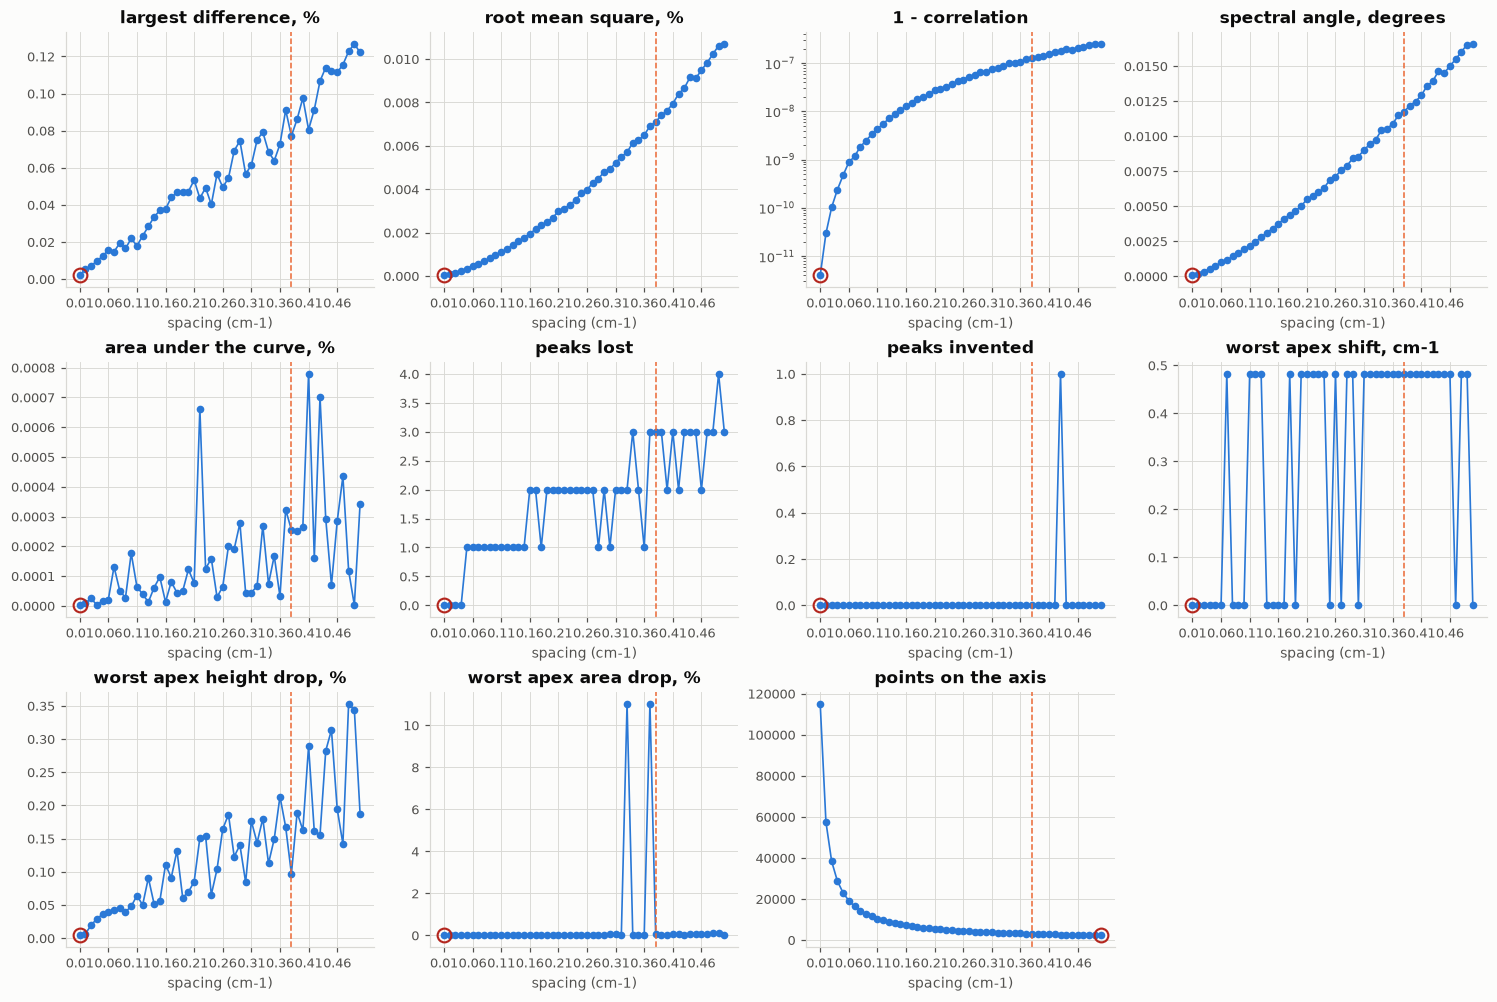

In [8]:
# The fixed spacing the note above records, and the range searched around it. The range spans the
# spacings the RRUFF files are written on and the fixed spacing together, so that a candidate coarser
# than the files and one finer than every file are read on the same columns. Every candidate goes
# through the same measurement as section 5, so the columns are comparable and their shapes can be
# read against one another.
FIXED_SPACING = 0.38
SEARCHED = [round(0.01 + 0.01 * index, 2) for index in range(50)]

costs = [(spacing, closeness(spacing)) for spacing in SEARCHED]
at_spacing = {spacing: peaks_against(one) for spacing, one in costs}


def area_under_curve(one):
    """The area under the pre-processed curve against the file's, over the common range, as a
    percent of the file's area.

    Args:
        one (dict): one spacing's cost, as `closeness` returns it.

    Returns:
        float: the change in area, signed.
    """
    inside = (x >= one["low"]) & (x <= one["high"])
    grid_x = x[inside]
    file_area = np.trapezoid(one["measured"][inside], grid_x)
    model_area = np.trapezoid(np.interp(grid_x, one["axis"], one["preprocessed"]), grid_x)
    return 100.0 * float(model_area / file_area - 1.0)


# Every metric the notebook reports, as a function of one spacing's results. The drops are taken as
# magnitudes and the area change likewise, so that the smallest value in a panel is the best one.
METRICS = (
    ("largest difference, %", lambda one, peak: one["largest"], False),
    ("root mean square, %", lambda one, peak: one["rms"], False),
    ("1 - correlation", lambda one, peak: 1.0 - one["correlation"], True),
    ("spectral angle, degrees", lambda one, peak: one["angle"], False),
    ("area under the curve, %", lambda one, peak: abs(area_under_curve(one)), False),
    ("peaks lost", lambda one, peak: float(peak["lost"]), False),
    ("peaks invented", lambda one, peak: float(peak["created"]), False),
    ("worst apex shift, cm-1", lambda one, peak: abs(peak["shift_largest"]), False),
    ("worst apex height drop, %", lambda one, peak: abs(peak["height_worst"]), False),
    ("worst apex area drop, %", lambda one, peak: abs(peak["area_worst"]), False),
    ("points on the axis", lambda one, peak: float(one["points"]), False),
)

scores = {label: [value(one, at_spacing[spacing]) for spacing, one in costs]
          for label, value, _ in METRICS}

print(f"the fixed spacing is {FIXED_SPACING} cm-1; the range searched is {SEARCHED[0]:.2f} to "
      f"{SEARCHED[-1]:.2f} cm-1 in steps of 0.01")
print()
print(f"{'spacing':>8} {'points':>8} {'largest%':>9} {'rms%':>8} {'SAM':>8} {'lost':>5} "
      f"{'shift':>7} {'height%':>8} {'area%':>8}")
for spacing, one in costs:
    peak = at_spacing[spacing]
    print(f"{spacing:8.2f} {one['points']:8,d} {one['largest']:9.4f} {one['rms']:8.4f} "
          f"{one['angle']:8.4f} {peak['lost']:5,d} {abs(peak['shift_largest']):7.3f} "
          f"{abs(peak['height_worst']):8.3f} {abs(peak['area_worst']):8.3f}")

def shown(value):
    """A table entry: four decimals, or scientific notation when the number is too small for four
    decimals to show anything but a zero."""
    return f"{value:.3e}" if 0.0 < abs(value) < 5e-4 else f"{value:.4f}"


fixed_one = closeness(FIXED_SPACING)
fixed_peak = peaks_against(fixed_one)
print()
print(f"{'metric':<26} {'at 0.38':>9} {'best':>9} {'best at':>8} {'points':>8}")
for label, value, _ in METRICS:
    best_index = int(np.argmin(scores[label]))
    print(f"{label:<26} {shown(value(fixed_one, fixed_peak)):>9} "
          f"{shown(scores[label][best_index]):>9} {SEARCHED[best_index]:8.2f} "
          f"{costs[best_index][1]['points']:8,d}")

# One panel per metric, the spacing along the x axis, with the fixed spacing marked and the best of
# the range ringed. The one metric on a log scale falls by a factor across the range rather than by
# an amount, so a linear axis would hide its shape.
COLUMNS = 4
rows = -(-len(METRICS) // COLUMNS)
figure, grid = plt.subplots(rows, COLUMNS, figsize=(13.5, 3.0 * rows), constrained_layout=True)
for panel, (label, _, log) in zip(grid.ravel(), METRICS):
    values = scores[label]
    panel.plot(SEARCHED, values, color=BLUE, marker="o", ms=4.0, lw=1.1)
    panel.axvline(FIXED_SPACING, color=ORANGE, lw=1.0, ls="--")
    best_index = int(np.argmin(values))
    panel.plot([SEARCHED[best_index]], [values[best_index]], marker="o", ms=9,
               mfc="none", mec=FLAG, mew=1.4)
    panel.set_title(label)
    panel.set_xlabel("spacing (cm-1)")
    panel.set_xticks(SEARCHED[::5])
    if log:
        panel.set_yscale("log")
for panel in grid.ravel()[len(METRICS):]:
    panel.set_visible(False)
plt.show()


### The same search from 0.400 down to 0.300 cm-1, at a hundredth of the step

The cell below repeats the measurement of the previous one on a range a hundred times finer, every
spacing from 0.400 down to 0.300 cm-1 in steps of 0.001. The fixed spacing, the peak windows and
the apex detection are the same, so a row here can be read against a row there, and the panels
carry all 101 candidates rather than a sample of them.


The range is a hundred times finer than the one above, and what it answers is the same size.
None of the 101 candidates puts the axis on the file's own points, which needs a spacing that
divides 0.4821 cm-1, and the only such spacing is 0.24105, below this range: as in the sweep above,
what moves these columns is the phase of the axis against the file's grid, not alignment with it.

The finer step exposes what the coarser one could not show, that the largest difference is not a
smooth function of the spacing. Read over the three thousandths of a centimetre below the fixed
spacing at a resolution of a hundred-thousandth, it runs from 0.0653% to 0.0980% and takes seven
separate low points. Over the whole 0.300 to 0.400 cm-1 sweep, at the step this cell uses, it runs
from 0.0567% to 0.1029%. A window one thirty-third as wide nearly covers the range of values the
whole sweep covers, so the value at any one candidate is mostly the phase it landed on, and the
panels are those phases sampled at a hundredth, which is why they read as jagged rather than
smooth.

What the sweep does resolve is the spacing itself. Every curve metric improves as the axis narrows,
the largest difference from 0.0976% at 0.400 cm-1 to 0.0567% at 0.300, the root mean square from
0.0076% to 0.0049%, the spectral angle from 0.0125 to 0.0085 degrees, the correlation likewise at
1.254e-07 against 6.640e-08, at the price of the axis, 2,875 points against 3,834. None of them has
an optimum inside this range: they ask for a finer axis without limit, and nine tenths of the range
lies below 0.39 cm-1, the finest grid any file here is written on, so those points are read off the
same file points by interpolation rather than measuring anything new. What puts a floor under the
spacing is the files, not these metrics.

The peak columns settle nothing either. Peaks lost runs from 1 to 4 with no trend in the spacing;
the worst apex shift is one step of the file's grid, 0.4821 cm-1, at nearly every candidate and zero
at a few (0.300, 0.315 and 0.363), where the model's apex lands on the file point the file's own
apex occupies; and the worst apex area drop jumps to about 11% at a scattering of candidates, among
the rows printed 0.330, 0.345, 0.370, 0.375, 0.376, 0.384 and 0.385, which is the window talking
rather than the resampling, as in the sweep above. The area under the whole curve is a different
column, and it stays under a thousandth of a percent at every candidate, which is why the summary
table prints it in scientific notation.

Within a hundredth of the fixed spacing the eleven candidates are 0.376 to 0.384, and 0.38 is the
best of them on the largest difference, 0.0772% against 0.0847% to 0.0988% around it, and close to
the best on the spectral angle and on the worst apex height drop, 0.0117 degrees and 0.097%, where
0.378 gives 0.0115 degrees and 0.382 gives 0.094%. Read with the fine structure above, that makes
0.38 a good draw from the phases a hundredth of itself offers, which is a weaker claim than being a
value the metrics single out, and it is the honest one: the metric tables record which spacing wins
each column, not a spacing that wins them all.


the fixed spacing is 0.38 cm-1; this range is 0.400 down to 0.300 cm-1 in steps of 0.001, 101 candidates
candidates whose axis lands exactly on the file's own points: 0 of 101, so every shape below is phase rather than alignment
the largest difference over 0.3770 to 0.3800 cm-1, read at 1e-5, runs from 0.0653% to 0.0980%, taking a low point 7 times
the same metric over the whole 0.300 to 0.400 cm-1 sweep, read at 0.001, runs from 0.0567% to 0.1029%
the area under the whole curve over the sweep stays between 6.5e-07% and 9.3e-04%

every fifth candidate is printed, and the panels below carry all 101
 spacing   points  largest%     rms%      SAM  lost   shift  height%    area%
   0.400    2,875    0.0976   0.0076   0.0125     2   0.482    0.163    0.024
   0.395    2,912    0.0855   0.0075   0.0124     3   0.482    0.248    0.024
   0.390    2,949    0.0862   0.0074   0.0122     3   0.482    0.189    0.025
   0.385    2,988    0.0962   0.0072   0.0119     3   0.482    0.196   11.019
   0.

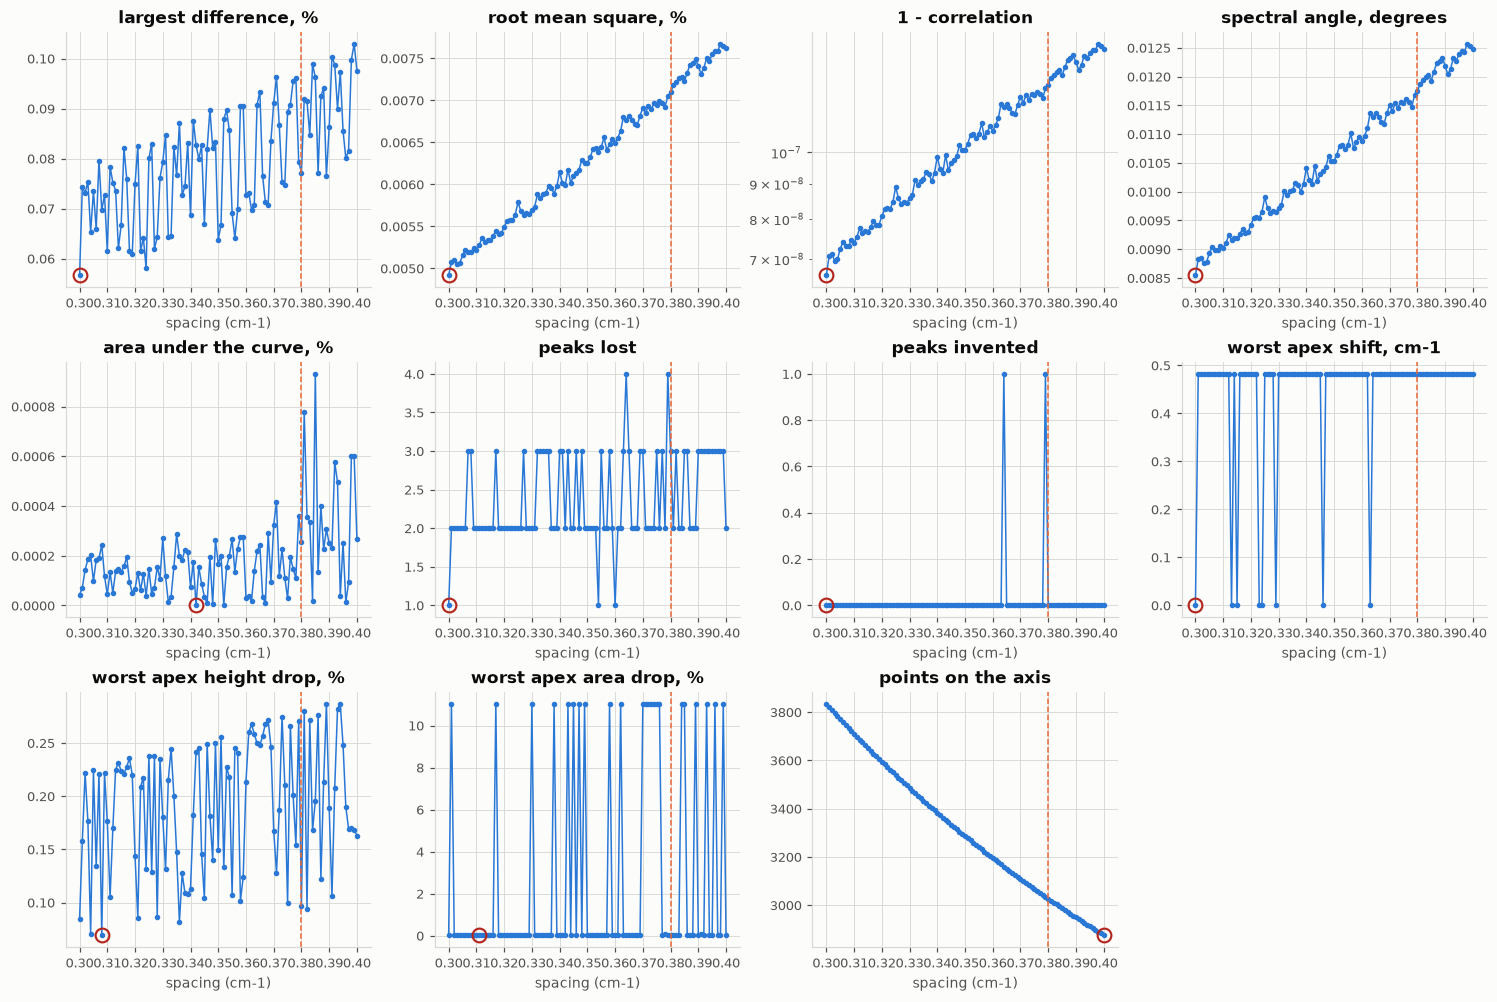

In [9]:
# The same measurement as the search above, on a range a hundred times finer: every spacing from
# 0.400 down to 0.300 cm-1 in steps of 0.001, which brackets the fixed 0.38 on both sides and
# reaches the spacing the smallest files in the data are written on.
FINE_STEP = 0.001
FINE_SEARCHED = [round(0.4 - FINE_STEP * index, 3) for index in range(101)]

fine_costs = [(spacing, closeness(spacing)) for spacing in FINE_SEARCHED]
fine_at_spacing = {spacing: peaks_against(one) for spacing, one in fine_costs}


def area_under_curve(one):
    """The area under the pre-processed curve against the file's, over the common range, as a
    percent of the file's area.

    Args:
        one (dict): one spacing's cost, as `closeness` returns it.

    Returns:
        float: the change in area, signed.
    """
    inside = (x >= one["low"]) & (x <= one["high"])
    grid_x = x[inside]
    file_area = np.trapezoid(one["measured"][inside], grid_x)
    model_area = np.trapezoid(np.interp(grid_x, one["axis"], one["preprocessed"]), grid_x)
    return 100.0 * float(model_area / file_area - 1.0)


# The same metrics as the search above, in the same order, so the two sets of panels can be put
# side by side.
METRICS = (
    ("largest difference, %", lambda one, peak: one["largest"], False),
    ("root mean square, %", lambda one, peak: one["rms"], False),
    ("1 - correlation", lambda one, peak: 1.0 - one["correlation"], True),
    ("spectral angle, degrees", lambda one, peak: one["angle"], False),
    ("area under the curve, %", lambda one, peak: abs(area_under_curve(one)), False),
    ("peaks lost", lambda one, peak: float(peak["lost"]), False),
    ("peaks invented", lambda one, peak: float(peak["created"]), False),
    ("worst apex shift, cm-1", lambda one, peak: abs(peak["shift_largest"]), False),
    ("worst apex height drop, %", lambda one, peak: abs(peak["height_worst"]), False),
    ("worst apex area drop, %", lambda one, peak: abs(peak["area_worst"]), False),
    ("points on the axis", lambda one, peak: float(one["points"]), False),
)

fine_scores = {label: [value(one, fine_at_spacing[spacing]) for spacing, one in fine_costs]
               for label, value, _ in METRICS}

print(f"the fixed spacing is {FIXED_SPACING} cm-1; this range is {FINE_SEARCHED[0]:.3f} down to "
      f"{FINE_SEARCHED[-1]:.3f} cm-1 in steps of {FINE_STEP:.3f}, {len(FINE_SEARCHED)} candidates")
# A candidate whose axis lands on the file's own points leaves the curve exactly as it is, and the
# sawtooth in the panels turns on how close a candidate comes to that. The file's own points sit
# 0.4821 cm-1 apart, so those spacings are 0.4821 divided by a whole number.
landing = [spacing for spacing in FINE_SEARCHED
           if any(abs(SPACING / divisor - spacing) < 1e-9 for divisor in range(1, 5))]
print(f"candidates whose axis lands exactly on the file's own points: {len(landing)} of "
      f"{len(FINE_SEARCHED)}, so every shape below is phase rather than alignment")

# What the panels cannot show at the step they are drawn with: the largest difference is not a
# smooth function of the spacing. This walks the three thousandths of a centimetre below the fixed
# spacing at a resolution of a hundred-thousandth, and reports the range it covers there beside the
# range the sweep itself covers.
detail_window = [round(FIXED_SPACING - 3e-3 + 1e-5 * index, 6) for index in range(301)]
detail_walk = np.array([closeness(spacing)["largest"] for spacing in detail_window])
lowest = [index for index in range(1, detail_walk.size - 1)
          if detail_walk[index] < detail_walk[index - 1]
          and detail_walk[index] <= detail_walk[index + 1]]
swept_largest = np.asarray(fine_scores["largest difference, %"])
swept_area = np.asarray(fine_scores["area under the curve, %"])
print(f"the largest difference over {detail_window[0]:.4f} to {detail_window[-1]:.4f} cm-1, read "
      f"at 1e-5, runs from {detail_walk.min():.4f}% to {detail_walk.max():.4f}%, taking a low "
      f"point {len(lowest)} times")
print(f"the same metric over the whole {FINE_SEARCHED[-1]:.3f} to {FINE_SEARCHED[0]:.3f} cm-1 "
      f"sweep, read at {FINE_STEP:.3f}, runs from {swept_largest.min():.4f}% to "
      f"{swept_largest.max():.4f}%")
# The per-candidate table has an area column of its own, which is the window one apex is integrated
# over and can move by tens of percent when that window lands on different grid points. This is the
# other area, the whole range, and it behaves nothing like it.
print(f"the area under the whole curve over the sweep stays between {swept_area.min():.1e}% and "
      f"{swept_area.max():.1e}%")

print()
print("every fifth candidate is printed, and the panels below carry all 101")
print(f"{'spacing':>8} {'points':>8} {'largest%':>9} {'rms%':>8} {'SAM':>8} {'lost':>5} "
      f"{'shift':>7} {'height%':>8} {'area%':>8}")
for index, (spacing, one) in enumerate(fine_costs):
    if index % 5 and index != len(fine_costs) - 1:
        continue
    peak = fine_at_spacing[spacing]
    print(f"{spacing:8.3f} {one['points']:8,d} {one['largest']:9.4f} {one['rms']:8.4f} "
          f"{one['angle']:8.4f} {peak['lost']:5,d} {abs(peak['shift_largest']):7.3f} "
          f"{abs(peak['height_worst']):8.3f} {abs(peak['area_worst']):8.3f}")

# The fixed spacing's own neighbourhood, at the resolution this range resolves: the candidates
# within half a hundredth of 0.38, which is what the choice of 0.38 actually buys.
print()
print(f"the candidates within {5 * FINE_STEP:.3f} cm-1 of the fixed {FIXED_SPACING}:")
print(f"{'spacing':>8} {'points':>8} {'largest%':>9} {'rms%':>8} {'SAM':>8} {'lost':>5} "
      f"{'shift':>7} {'height%':>8} {'area%':>8}")
for spacing, one in fine_costs:
    if abs(spacing - FIXED_SPACING) > 5 * FINE_STEP:
        continue
    peak = fine_at_spacing[spacing]
    print(f"{spacing:8.3f} {one['points']:8,d} {one['largest']:9.4f} {one['rms']:8.4f} "
          f"{one['angle']:8.4f} {peak['lost']:5,d} {abs(peak['shift_largest']):7.3f} "
          f"{abs(peak['height_worst']):8.3f} {abs(peak['area_worst']):8.3f}")

def shown(value):
    """A table entry: four decimals, or scientific notation when the number is too small for four
    decimals to show anything but a zero."""
    return f"{value:.3e}" if 0.0 < abs(value) < 5e-4 else f"{value:.4f}"


fixed_one = closeness(FIXED_SPACING)
fixed_peak = peaks_against(fixed_one)
print()
print(f"{'metric':<26} {'at 0.38':>9} {'best':>9} {'best at':>8} {'points':>8}")
for label, value, _ in METRICS:
    best_index = int(np.argmin(fine_scores[label]))
    print(f"{label:<26} {shown(value(fixed_one, fixed_peak)):>9} "
          f"{shown(fine_scores[label][best_index]):>9} {FINE_SEARCHED[best_index]:8.3f} "
          f"{fine_costs[best_index][1]['points']:8,d}")

# One panel per metric, the spacing along the x axis, with the fixed spacing marked and the best of
# the range ringed. The panels are drawn with the spacing increasing to the right, which is the
# reverse of the order searched, because the range reads more easily that way. The one metric on a
# log scale falls by a factor across the range rather than by an amount.
order = np.argsort(FINE_SEARCHED)
swept = [FINE_SEARCHED[index] for index in order]
COLUMNS = 4
rows = -(-len(METRICS) // COLUMNS)
figure, grid = plt.subplots(rows, COLUMNS, figsize=(13.5, 3.0 * rows), constrained_layout=True)
for panel, (label, _, log) in zip(grid.ravel(), METRICS):
    values = [fine_scores[label][index] for index in order]
    panel.plot(swept, values, color=BLUE, marker="o", ms=2.6, lw=1.0)
    panel.axvline(FIXED_SPACING, color=ORANGE, lw=1.0, ls="--")
    best_index = int(np.argmin(values))
    panel.plot([swept[best_index]], [values[best_index]], marker="o", ms=9, mfc="none",
               mec=FLAG, mew=1.4)
    panel.set_title(label)
    panel.set_xlabel("spacing (cm-1)")
    panel.set_xticks(swept[::10])
    if log:
        panel.set_yscale("log")
for panel in grid.ravel()[len(METRICS):]:
    panel.set_visible(False)
plt.show()


## 8. What this covers

| Section | Reports |
| --- | --- |
| 2 | where the repository samples the intensity, and what each line there decides |
| 3 | the function, written out on its own |
| 4 | one spectrum of the selected set, sampled, and the two grids at a readable scale |
| 5 | what the resampling costs that spectrum, across the shared range and per peak, and the panels that draw what each metric reads |
| 6 | the spacing the metrics are read at, and why it is 0.38 |
| 7 | what each spacing from 0.01 to 0.50 cm-1 costs and buys, metric by metric, and again from 0.400 down to 0.300 cm-1 at a hundredth of that step |
| 10 | the spacing chosen for the interpolation, and what the columns above read at it |
| 11 | the four functions that augment a spectrum, copied from `src/cnn/cnn_preprocessing.py`, and what two of them do to the spectrum of section 4 |

The axis standardised to is this notebook's own: the window the selected set is built on, read
at an exact 0.4821 cm-1 step. Both numbers, and the rule that builds the window, come from
`notebooks/selected_data_eda.ipynb`. The repository's own sampling is described in section 2,
but the notebook no longer runs it.


## 9. Reproducing

```
cd /home/raj/projects/SH_Project
jupyter execute --inplace --kernel_name sh_project notebooks/preprocessing_data.ipynb
```

The notebook reads one archive from `~/Desktop/raman_data`, or from `RRUFF_DATA` when that is
set.


## 10. The spacing chosen for the interpolation

The searches above report what each candidate spacing costs on every column. This section records
the decision taken from them, and what it rests on.

A spacing of 0.01 cm-1 is chosen. The resolution is kept very fine to minimise the information loss due to interpolation.

On the columns of section 7, that candidate is the finest of the fifty and the smallest value on
every column but the point count: the largest difference 0.0020% against 0.1268% at the coarsest,
the root mean square 3.035e-05%, the spectral angle 6.651e-05 degrees, the correlation written
1 - r 4.024e-12, no peaks lost and none invented, the worst apex shift zero, and the worst apex
height and area drops 0.0043% and 0.0015%. It carries 115,000 points on the axis, against 2,300 at
0.50 cm-1 and 3,027 at the fixed 0.38.

The finest grid any file in this set is written on is 0.39 cm-1, so the axis at 0.01 cm-1 holds those
points and the interpolated values between them, and no point on it is a measurement the file does
not already carry.


## 11. How the repository augments a spectrum

The four functions below are copied unchanged from `src/cnn/cnn_preprocessing.py`, which is where
the augmentation lives. They take the standardised spectra the model takes, one spectrum per call
shaped `(points, 1)`, and each returns the same shape.

- `augment_shift` moves the whole spectrum along the axis by a whole number of points, drawn from
  -5 to 5 with zero redrawn, and fills the stretch the roll wrapped around with zero. On the axis of
  section 2 a point is 0.4821 cm-1, so the move reaches 2.4105 cm-1 either way. The paper asks for
  each spectrum to be shifted left or right "a few wavenumbers randomly"; this is that, counted in
  axis steps rather than in wavenumbers.
- `augment_noise` adds Gaussian noise whose standard deviation is a tenth of the intensity at each
  point, so the noise follows the spectrum's own magnitude; it then clips at zero and renormalises
  the copy to a peak of one. The paper's noise "proportional to the magnitude at each wave number"
  is the standard deviation here.
- `augment_linear_combinations` mixes every pair of spectra in a class, each pair once, with a
  coefficient drawn uniformly between 0 and 1, and renormalises the mixture. A class of `n` spectra
  gives `n(n-1)/2` mixtures, so a class of two gives one and the median class of the selected set,
  which holds between two and a few spectra, gives a handful.
- `build_augmented_dataset` is what training calls. It adds `n_shift` shifted copies and `n_noise`
  noised copies of every original, then one mixture per pair within each class, and returns the
  originals together with the whole augmented set. No transform ever consumes another transform's
  output: the copies are made from originals only, which is what keeps a run's distortions from
  compounding.

The generator is handed to each function rather than drawn from `np.random` inside it, so what a run
augments depends on that run's seed and on nothing else that happens to be drawing.

The copy of `build_augmented_dataset` logs its counts through the module's logger, so the cell below
gives it one: without it the function raises on the name the moment it is called. That logger is the
only line the cell adds to the code.

The cell then runs the two transforms that take a single spectrum on the spectrum of section 4, which
is real data, and draws what they did. The mixture transform takes a class and this notebook reads one
spectrum, so it is shown in the source only. How far the shift may reach, the tenth of the intensity
the noise uses, and how many copies a run asks for are all values the source fixes and the paper does
not give; the notebook records them here without changing them.


the spectrum put in: 2,386 points, shaped (2386, 1), peak 1.0000, 0 points at zero of its own
  the shift copy: moved 4 points to the right, 1.9284 cm-1 at this spacing, and filled 4 points with zero, shaped (2386, 1)
  the noise copy: shaped (2386, 1), peak 1.0000 after the renormalisation, largest change from the original 0.2773
  the mixtures this notebook cannot make: one per pair in a class, so 1 for a class of two and 3 for a class of three


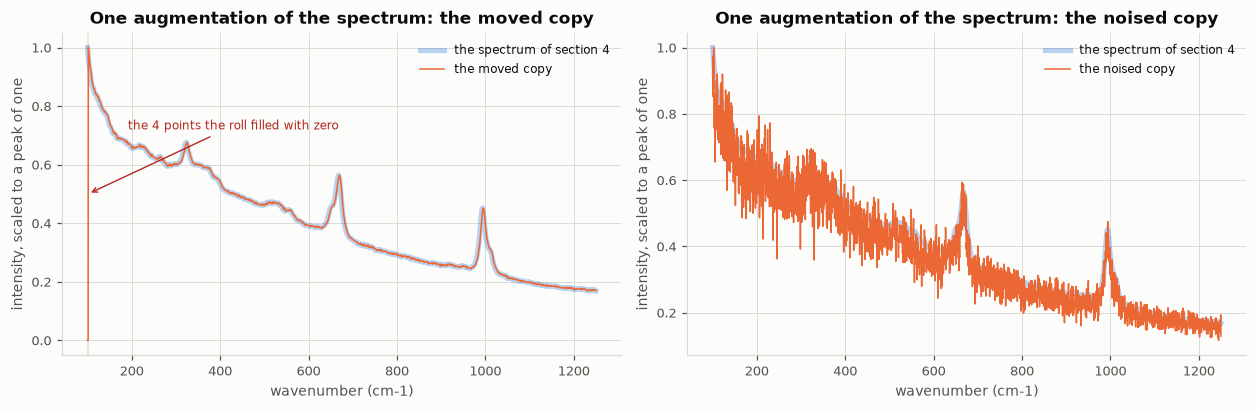

In [10]:
# `build_augmented_dataset` reports its counts through the module's logger, so the copy of it above
# needs one to be callable. An INFO message with no handler configured is dropped, so the logger
# stays quiet and nothing about the notebook's own output changes.
import logging

logger = logging.getLogger("cnn_preprocessing")

def augment_shift(spectrum, rng):
    """A copy of the spectrum moved along the axis by a random number of points.

    Args:
        spectrum: One standardised spectrum, shaped (points, 1).
        rng (np.random.Generator): The run's generator. Passed in rather than drawn from
            ``np.random`` so that a run's augmentations depend on its seed and on nothing
            else that happens to be drawing from the global generator.
    """
    intensity = spectrum[:, 0].copy() # again, the shape is (target_length, 1)

    # generate some random shift integer val between -5 and 5
    shift = rng.integers(-5, 6)
    # shifts = 0 do nothing
    while shift == 0:
        shift = rng.integers(-5, 6)

    # use numpy roll to shift for its quickness
    intensity = np.roll(intensity, shift)
    # np roll wraps, replace values to 0 that were wrapped around
    if shift > 0:
        intensity[:shift] = 0
    else:
        intensity[shift:] = 0

    # reshape to fit CNN model's req
    spectrum = intensity.reshape(-1, 1)
    return spectrum

def augment_noise(spectrum, rng):
    """A copy of the spectrum with noise added in proportion to its own intensity."""
    intensity = spectrum[:, 0].copy()
    noise = rng.normal(0, 0.1 * np.abs(intensity))

    # clip to stay bounded between 0 and inf
    intensity = np.clip(intensity + noise, 0, None)
    # normalise
    intensity /= (intensity.max() + 1e-8)
    # reshape to fit CNN model's req
    spectrum = intensity.reshape(-1, 1)
    return spectrum

def augment_linear_combinations(spectra_for_class, rng):
    """Every pair of spectra in a class mixed by a random coefficient."""
    augmented = []
    n = len(spectra_for_class)
    if n < 2:
        return augmented

    # all unique pairs
    for i in range(n):
        for j in range(i + 1, n):
            coeff = rng.uniform(0, 1)
            combined_intensity = (
                coeff * spectra_for_class[i][:, 0] +
                (1 - coeff) * spectra_for_class[j][:, 0]
            )
            combined_intensity /= (combined_intensity.max() + 1e-8)
            augmented.append(combined_intensity.reshape(-1, 1))
    return augmented

def build_augmented_dataset(x_train, y_train_labels, n_shift, n_noise, rng):
    """The originals plus their augmented copies, and their labels.

    Augmentation is applied to the originals only, never to an augmented spectrum, so a
    run's augmented set is ``n_shift + n_noise`` copies plus one combination per pair of
    spectra within a class.
    """

    original_x  = list(x_train)
    original_y  = list(y_train_labels)
    augmented_x = []
    augmented_y = []

    # collect the spectras grouped by classes
    # running hash map appraoch
    class_spectra = {}
    for spectrum, label in zip(x_train, y_train_labels):
        if label not in class_spectra:
            class_spectra[label] = []
        class_spectra[label].append(spectrum)

    for label, spectra_list in class_spectra.items():

        for spectrum in spectra_list:

            # shift augmentation on originals only
            for _ in range(n_shift):
                augmented_x.append(augment_shift(spectrum, rng))
                augmented_y.append(label)

            # noise augmentation on originals only
            for _ in range(n_noise):
                augmented_x.append(augment_noise(spectrum, rng))
                augmented_y.append(label)

        # augment by linear combinations
        combos = augment_linear_combinations(spectra_list, rng)
        for combo in combos:
            augmented_x.append(combo)
            augmented_y.append(label)


    # originals + augmented, never augmenting augmented data
    x_all = np.array(original_x + augmented_x)
    y_all = np.array(original_y + augmented_y)

    logger.info("Original samples:            %s", len(original_x))
    logger.info("Shift augmented:             %s", n_shift * len(x_train))
    logger.info("Noise augmented:             %s", n_noise * len(x_train))
    logger.info("Linear combinations:         %s", len(augmented_x) - n_shift * len(x_train) - n_noise * len(x_train))
    logger.info("Total augmented samples:     %s", len(augmented_x))
    logger.info("Total samples:               %s", len(x_all))
    logger.info("Augmentation multiplier:     %.1fx", len(x_all) / len(original_x))

    return x_all, y_all

# The augmentation takes and returns one spectrum shaped (points, 1), which is what the model takes,
# so the spectrum of section 4 is put into that shape here.
one = sampled.reshape(-1, 1)

# A generator of its own, so what this cell draws is the same on every run and does not depend on
# anything else that has drawn from np.random.
demo_rng = np.random.default_rng(0)
shifted = augment_shift(one, demo_rng)
noised = augment_noise(one, demo_rng)

# The transform returns the copy but not the shift it drew, and this spectrum holds no zero point of
# its own, so the zeros the copy gained are the stretch the roll filled and their count is the
# distance moved. Which end they sit at says which way the copy went.
filled = int(np.count_nonzero(shifted[:, 0] == 0.0))
way = "right" if shifted[0, 0] == 0.0 else "left"
zeros_of_its_own = int(np.count_nonzero(one[:, 0] == 0.0))

print(f"the spectrum put in: {one.shape[0]:,} points, shaped {one.shape}, peak "
      f"{float(one.max()):.4f}, {zeros_of_its_own} points at zero of its own")
print(f"  the shift copy: moved {filled} points to the {way}, {filled * SPACING:.4f} cm-1 at this "
      f"spacing, and filled {filled} points with zero, shaped {shifted.shape}")
print(f"  the noise copy: shaped {noised.shape}, peak {float(noised.max()):.4f} after the "
      f"renormalisation, largest change from the original "
      f"{float(np.abs(noised[:, 0] - one[:, 0]).max()):.4f}")
print(f"  the mixtures this notebook cannot make: one per pair in a class, so 1 for a class of two "
      f"and 3 for a class of three")

# The original and the copy on the same axes, so the roughening of one and the fill of the other are
# both visible against what they were made from. The original is drawn wide and faint underneath,
# since a copy of four points' shift lies almost exactly on top of it and would hide it otherwise.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for panel, copy, name in ((axes[0], shifted, "moved"), (axes[1], noised, "noised")):
    panel.plot(AXIS, one[:, 0], color=BLUE, lw=3.4, alpha=0.32, label="the spectrum of section 4")
    panel.plot(AXIS, copy[:, 0], color=ORANGE, lw=1.0, label=f"the {name} copy")
    panel.set_title(f"One augmentation of the spectrum: the {name} copy")
    panel.set_xlabel("wavenumber (cm-1)")
    panel.set_ylabel("intensity, scaled to a peak of one")
    panel.legend(loc="upper right", fontsize=8)

# The stretch the roll filled with zero is the one part of the shift copy that differs from the
# original everywhere, so it is marked rather than left to be found in the first two points of the
# axis.
axes[0].axvspan(AXIS[0], AXIS[filled - 1], color=FLAG, alpha=0.16)
axes[0].annotate(f"the {filled} points the roll filled with zero",
                 xy=(AXIS[filled - 1], 0.5), xytext=(AXIS[filled - 1] + 90.0, 0.72),
                 fontsize=8, color=FLAG,
                 arrowprops=dict(arrowstyle="->", color=FLAG, lw=0.9))
plt.tight_layout()
plt.show()
